## Lab 3: Isomap

You can use external libraries for linear algebra operations (e.g. `numpy.linalg`) but you are expected to write your own Isomap algorithm, **including the shortest-path computation**.

### Notes
- You can use the `sklearn.neighbors.NearestNeighbors` class.
- You are expected to write your own implementation of the Floyd-Warshall algorithm, as seen in class (if you wish, you can implement Dijkstra's algorithm instead).
- Remember that your distance matrix must be symmetric!
- Test your algorithm with $n=100$ points at first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OrdinalEncoder

np.random.seed(42)

# Exercise 1
- Write your own implementation of Isomap.
- Apply it to the Swiss Roll dataset ($n=1000$) from Lab 1.

**Algorithm.**
1. Build the $k$-nearest-neighbour graph: the edge $(i,j)$ has weight $\|x_i-x_j\|$ if $j$ is among the $k$ nearest neighbours of $i$ **or** $i$ among those of $j$ (this makes the matrix symmetric), $+\infty$ otherwise.
2. Compute all-pairs shortest paths on the graph (Floyd-Warshall): the geodesic distances $D_G$.
3. Apply classical MDS to $D_G$: double centering $B=-\tfrac12 J D_G^{2} J$ with $J=I-\tfrac1n\mathbf 1\mathbf 1^T$, then the embedding is $V_d\Lambda_d^{1/2}$, with $(\lambda,v)$ the top $d$ eigenpairs of $B$.

In [2]:
def knn_graph(X, k):
    """Symmetric weighted k-NN graph as a dense matrix (np.inf = no edge, 0 on the diagonal)."""
    n = X.shape[0]
    dist, idx = NearestNeighbors(n_neighbors=k+1).fit(X).kneighbors(X)   # first neighbour is the point itself
    G = np.full((n, n), np.inf)
    for i in range(n):
        G[i, idx[i, 1:]] = dist[i, 1:]
    G = np.minimum(G, G.T)          # symmetrize: edge if i in kNN(j) OR j in kNN(i)
    np.fill_diagonal(G, 0)
    return G


def floyd_warshall(G):
    """All-pairs shortest paths. O(n^3), the two inner loops are vectorised with numpy."""
    D = G.copy()
    for m in range(D.shape[0]):                       # intermediate node
        D = np.minimum(D, D[:, m, None] + D[None, m, :])   # d(i,j) = min(d(i,j), d(i,m)+d(m,j))
    return D


class MyIsomap:
    def __init__(self, n_components=2, n_neighbors=10):
        self.n_components = n_components
        self.n_neighbors = n_neighbors

    def fit_transform(self, X):
        G = knn_graph(X, self.n_neighbors)
        D = floyd_warshall(G)
        if np.isinf(D).any():
            raise ValueError(f"The {self.n_neighbors}-NN graph is not connected: increase n_neighbors")
        self.geodesic_ = D
        n = D.shape[0]
        J = np.eye(n) - np.ones((n, n)) / n
        B = -0.5 * J @ (D**2) @ J                      # double centering
        eigval, eigvec = np.linalg.eigh(B)             # B is symmetric
        order = np.argsort(eigval)[::-1][:self.n_components]
        self.eigenvalues_ = eigval[order]
        self.embedding_ = eigvec[:, order] * np.sqrt(self.eigenvalues_)
        return self.embedding_

Test with a small dataset first, and sanity check against `sklearn.manifold.Isomap` (embeddings are defined up to a sign).

In [3]:
def swiss_roll(n, noise=0.0):
    """Swiss roll from Lab 1. Optionally adds N(0, noise) to the x and y coordinates. Returns data and phi."""
    data = np.zeros((n, 3))
    phi = np.random.uniform(low=1.5*np.pi, high=4.5*np.pi, size=n)
    psi = np.random.uniform(0, 10, n)
    data[:, 0] = phi*np.cos(phi) + np.random.normal(0, noise, n)   # x coordinate
    data[:, 1] = phi*np.sin(phi) + np.random.normal(0, noise, n)   # y coordinate
    data[:, 2] = psi                                               # z coordinate
    return data, phi

# sanity check on n = 100 points
from sklearn.manifold import Isomap
X100, phi100 = swiss_roll(100)
mine = MyIsomap(2, 8).fit_transform(X100)
ref = Isomap(n_components=2, n_neighbors=8, path_method='FW').fit_transform(X100)
D100 = floyd_warshall(knn_graph(X100, 8))
print("symmetric geodesic matrix:", np.allclose(D100, D100.T))
print("matches sklearn (up to sign):", np.allclose(np.abs(mine), np.abs(ref), atol=1e-6))

symmetric geodesic matrix: True
matches sklearn (up to sign): True


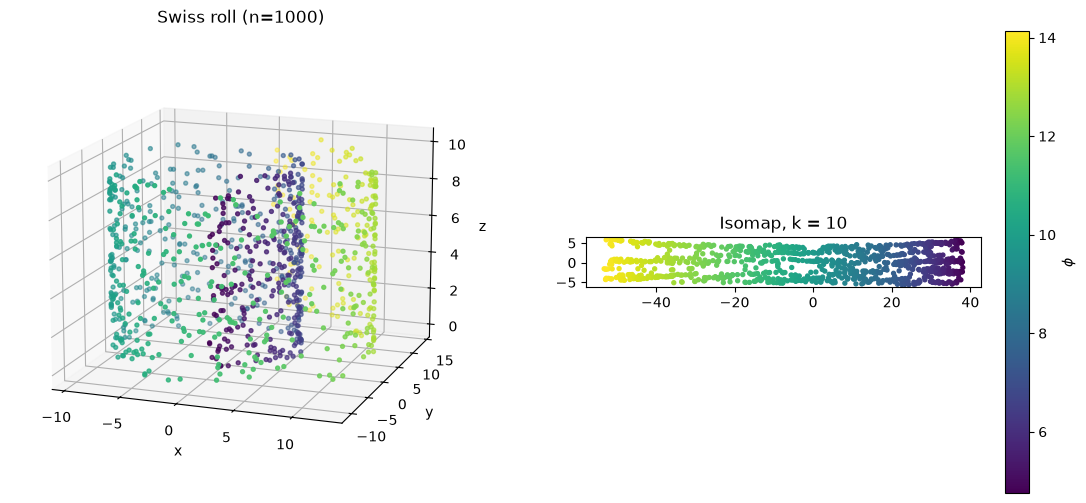

In [4]:
X, phi = swiss_roll(1000)

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=phi, s=8)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z'); ax.view_init(15, -70)
ax.set_title("Swiss roll (n=1000)")

Z = MyIsomap(2, 10).fit_transform(X)
ax2 = fig.add_subplot(1, 2, 2)
sc = ax2.scatter(Z[:, 0], Z[:, 1], c=phi, s=8)
plt.colorbar(sc, ax=ax2, label=r"$\phi$")
ax2.set_title("Isomap, k = 10"); ax2.set_aspect('equal')
plt.show()

**Choice of $k$.** Rule of thumb: the smallest $k$ that gives a fully connected graph; if $k$ is too large the graph contains *shortcuts* between adjacent turns of the roll and Isomap fails to unfold it. Let us try several values.

The 3-NN graph is not connected: increase n_neighbors


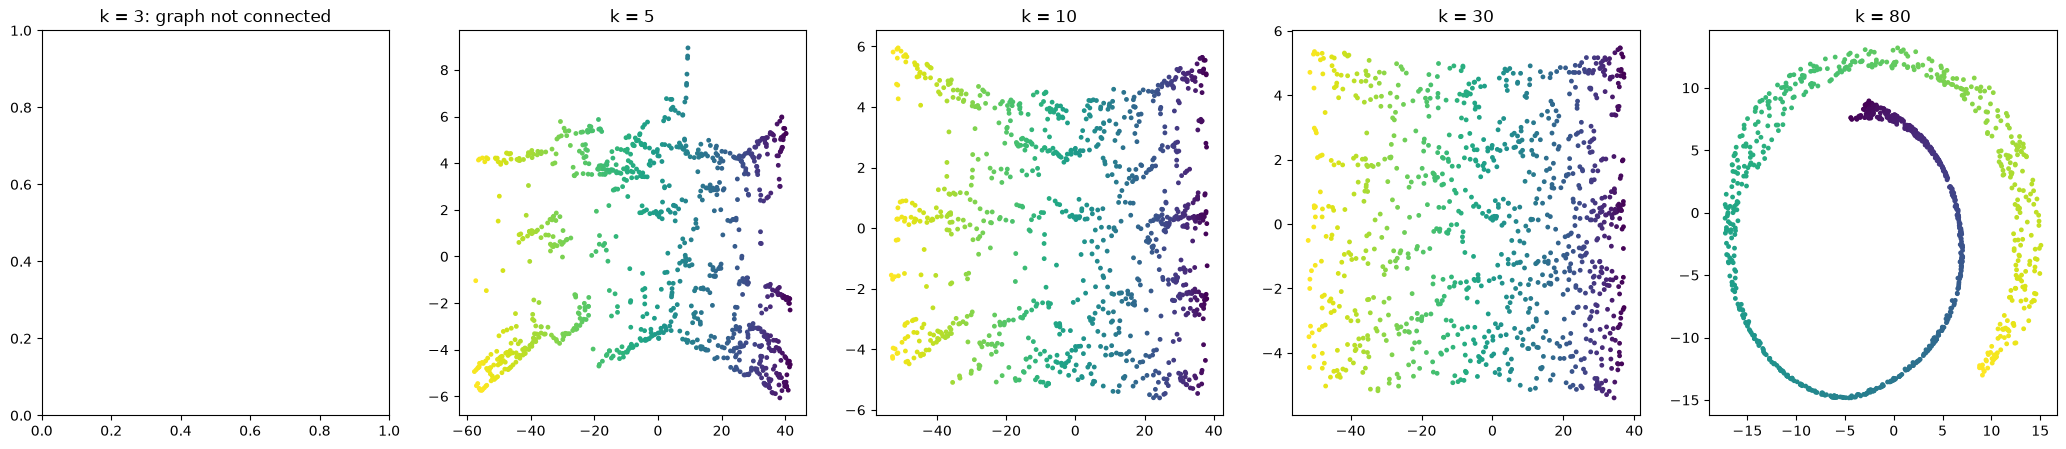

In [5]:
fig, ax = plt.subplots(1, 5, figsize=(26, 5))
for a, k in zip(ax, [3, 5, 10, 30, 80]):
    try:
        Zk = MyIsomap(2, k).fit_transform(X)
        a.scatter(Zk[:, 0], Zk[:, 1], c=phi, s=6)
        a.set_title(f"k = {k}")
    except ValueError as e:
        a.set_title(f"k = {k}: graph not connected"); print(e)
plt.show()

**Comment.** With $k=3$ the graph is not even connected (some points are isolated from the rest), and the minimum connected value here is around $k=5$. For $k=5$-$30$ Isomap **unrolls** the Swiss roll: the horizontal axis recovers the position along the roll ($\phi$, the colour changes smoothly from left to right), and the vertical axis the width $\psi$. This is exactly what PCA could not do in Lab 2. With only $n=1000$ points the sheet is sampled sparsely, so the strips are a bit irregular and show holes, and with a small $k$ the border of the strip is distorted. With $k=80$ the neighbourhood radius is larger than the distance between adjacent turns of the roll: the graph contains **shortcuts** through the empty space and the geodesic distances no longer follow the manifold, so the embedding collapses into a curved shape. Rule of thumb: take $k$ small, but large enough for a connected graph and a stable result.

- Use a modified version of the Swiss Roll dataset, in which Gaussian noise from a Normal $N(\mu=0,\sigma=0.5)$ is added to the $x$ and $y$ coordinates. Apply Isomap to this dataset and discuss the differences with the previous point.

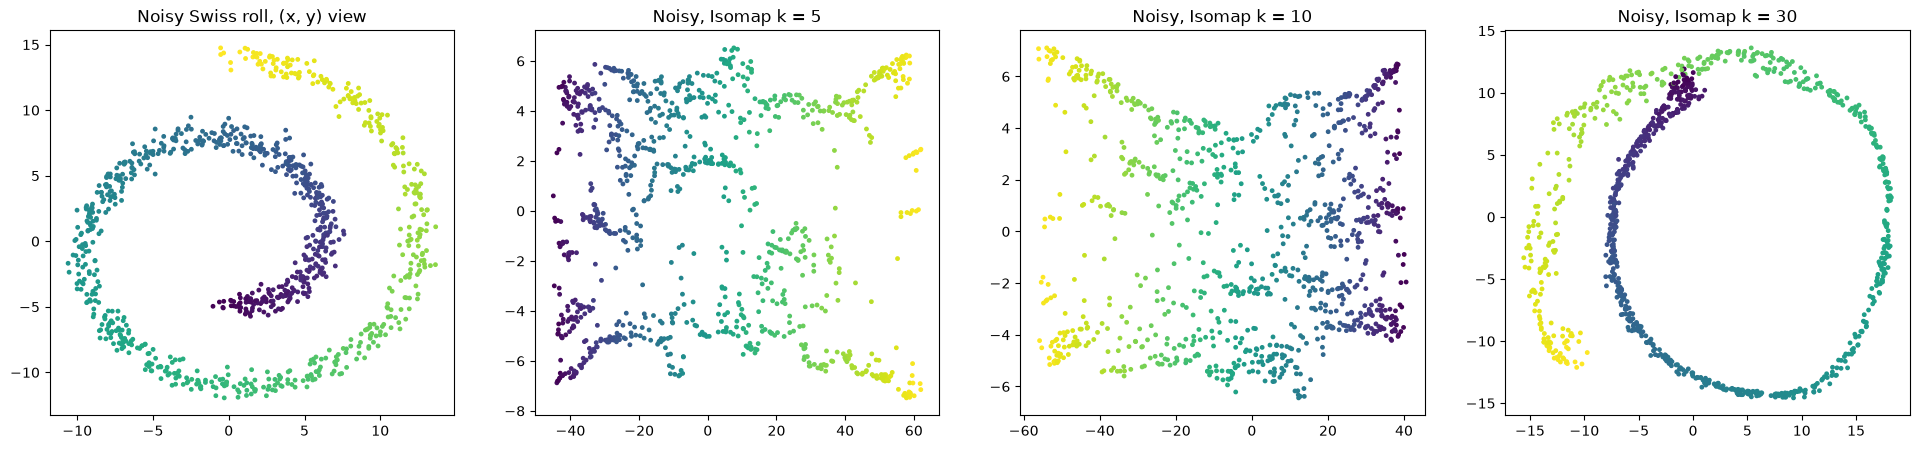

In [6]:
Xn, phin = swiss_roll(1000, noise=0.5)

fig, ax = plt.subplots(1, 4, figsize=(24, 5))
ax[0].scatter(Xn[:, 0], Xn[:, 1], c=phin, s=6); ax[0].set_title("Noisy Swiss roll, (x, y) view")
for a, k in zip(ax[1:], [5, 10, 30]):
    Zk = MyIsomap(2, k).fit_transform(Xn)
    a.scatter(Zk[:, 0], Zk[:, 1], c=phin, s=6); a.set_title(f"Noisy, Isomap k = {k}")
plt.show()

**Comment.** The noise thickens the roll, so points on adjacent turns get closer to each other. The same values of $k$ now behave worse: $k=5$ is very irregular (several fragments, since noisy points have unreliable neighbourhoods), $k=10$ still gives an unrolled strip but more distorted, and already at $k=30$ the shortcuts between adjacent turns appear (the embedding is again a spiral/circle) while the same $k$ was fine without noise. In general Isomap is **sensitive to noise** because the geodesic distance is built from the neighbourhood graph: a single wrong edge across two turns changes many shortest paths. The usable range of $k$ becomes narrower (small enough to avoid shortcuts, large enough to be connected and to average the noise) and the noise level must be small with respect to the distance between the turns.

# Exercise 2
Undersample randomly from the `Dry_Bean_Dataset.xlsx` in order to have $n=1000$ datapoints. Follow the same pipeline of Exercise 1 of the previous lab by replacing PCA with Isomap. Discuss the differences with particular focus on the accuracy of the logistic regression.

**Important note:** in this case you don't need to do the train-test split first. Apply Isomap to the whole (undersampled) dataset, then do the train-test split and follow the rest of the pipeline.

In [7]:
df = pd.read_excel("../Datasets/Dry_Bean_Dataset.xlsx")
classes = sorted(df['Class'].unique())
y = OrdinalEncoder().fit_transform(df[['Class']]).ravel()
X = df.drop('Class', axis=1).to_numpy(dtype=float)

# random undersampling to n = 1000 (stratified, to keep the class proportions)
X, _, y, _ = train_test_split(X, y, train_size=1000, random_state=42, stratify=y)
print(X.shape, np.bincount(y.astype(int)), classes)

# standardise (the whole dataset is used here, since Isomap is applied before the split)
X = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

(1000, 16) [ 97  38 120 260 142 149 194] ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


(1000, 16) eigenvalues of B: [17185.  6578.  2159.  1503.  1251.   693.]


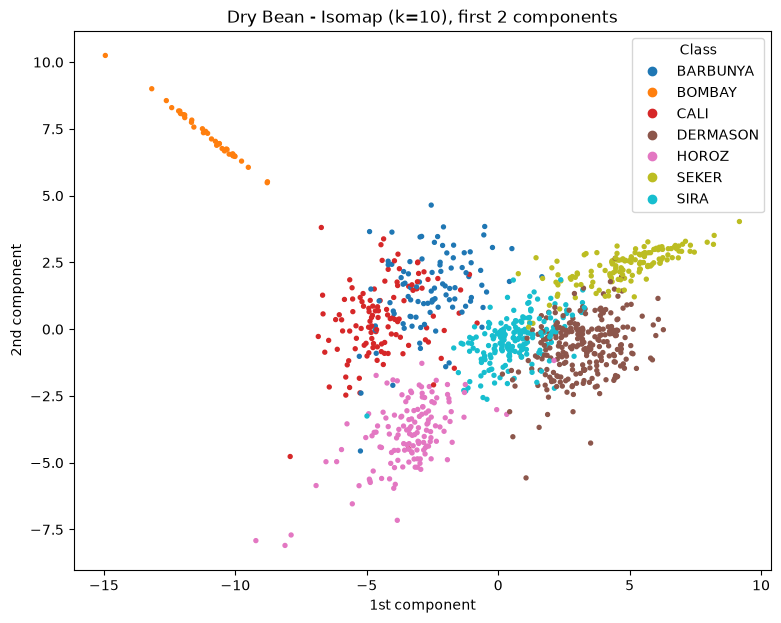

In [8]:
iso = MyIsomap(n_components=16, n_neighbors=10)
Z = iso.fit_transform(X)
print(Z.shape, "eigenvalues of B:", iso.eigenvalues_.round(0)[:6])

plt.figure(figsize=(9, 7))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=y, s=8, cmap="tab10")
plt.legend(handles=sc.legend_elements()[0], labels=classes, title="Class")
plt.xlabel("1st component"); plt.ylabel("2nd component"); plt.title("Dry Bean - Isomap (k=10), first 2 components")
plt.show()

In [9]:
# train-test split on the embedded data, then logistic regression with 1..16 components
Ztr, Zte, ytr, yte = train_test_split(Z, y, test_size=0.2, random_state=42, stratify=y)

score = []
for d in range(1, 17):
    lr = LogisticRegression(max_iter=5000).fit(Ztr[:, :d], ytr)
    score.append(lr.score(Zte[:, :d], yte))
    print(f"{d:2d} components: test accuracy = {score[-1]:.4f}")

 1 components: test accuracy = 0.6700
 2 components: test accuracy = 0.8550
 3 components: test accuracy = 0.8850
 4 components: test accuracy = 0.9200
 5 components: test accuracy = 0.9200
 6 components: test accuracy = 0.9100
 7 components: test accuracy = 0.9050
 8 components: test accuracy = 0.9000
 9 components: test accuracy = 0.9050
10 components: test accuracy = 0.9150
11 components: test accuracy = 0.9150
12 components: test accuracy = 0.9150
13 components: test accuracy = 0.9200
14 components: test accuracy = 0.9200
15 components: test accuracy = 0.9200
16 components: test accuracy = 0.9300


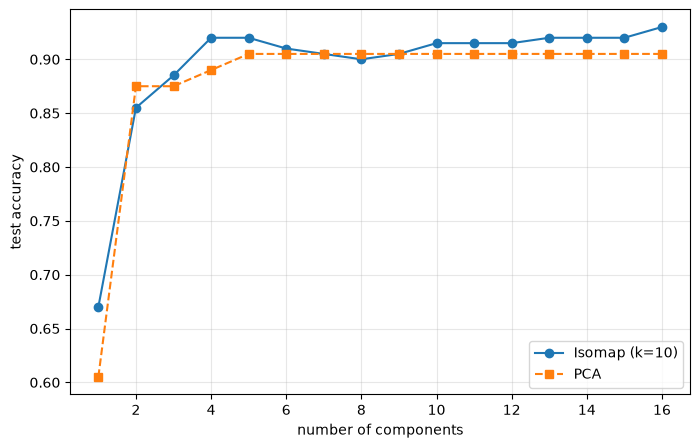

Isomap: max accuracy 0.9300 with 16 components
PCA:    max accuracy 0.9050 with 5 components


In [10]:
# baseline: same pipeline with PCA (own implementation of Lab 2: eigh of the covariance matrix)
eigval, eigvec = np.linalg.eigh(X.T @ X / (X.shape[0] - 1))
P = X @ eigvec[:, np.argsort(eigval)[::-1]]
Ptr, Pte, _, _ = train_test_split(P, y, test_size=0.2, random_state=42, stratify=y)
score_pca = [LogisticRegression(max_iter=5000).fit(Ptr[:, :d], ytr).score(Pte[:, :d], yte) for d in range(1, 17)]

plt.figure(figsize=(8, 5))
plt.plot(range(1, 17), score, "o-", label="Isomap (k=10)")
plt.plot(range(1, 17), score_pca, "s--", label="PCA")
plt.xlabel("number of components"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print(f"Isomap: max accuracy {max(score):.4f} with {int(np.argmax(score))+1} components")
print(f"PCA:    max accuracy {max(score_pca):.4f} with {int(np.argmax(score_pca))+1} components")

**Comment.** Isomap (own implementation, $k=10$) on the 16 standardised variables gives accuracies very close to PCA (Lab 2 pipeline): $\approx0.67$ with 1 component, $\approx0.86$ with 2, and about $0.92$ already with 4-5 components, then a plateau at $0.90$-$0.93$. Isomap is slightly above PCA for most dimensions (best 0.930 against 0.905), but the test set has only 200 points, so one point is $0.5\%$ and a difference of $2$-$3\%$ is not clearly significant. The reason why the two methods are so similar is that logistic regression is a *linear* classifier and the Dry Bean variables (size and shape descriptors) are strongly correlated and almost linear in the principal directions: the manifold here is close to a linear subspace, so the nonlinear unfolding of Isomap brings little. Notice also that Isomap is applied to the whole dataset (test points included), which is not possible in a standard supervised pipeline, where the test set must be mapped with the transformation learned on the training set.

## Bonus: the role of $k$ on Dry Bean
Repeat the previous experiment for different numbers of neighbours (using 5 components and several random train-test splits to reduce the noise of the estimate).

In [11]:
def acc_for_k(k, d=5, reps=10):
    Zk = MyIsomap(d, k).fit_transform(X)
    accs = []
    for seed in range(reps):
        a, b, ya, yb = train_test_split(Zk, y, test_size=0.2, random_state=seed, stratify=y)
        accs.append(LogisticRegression(max_iter=5000).fit(a, ya).score(b, yb))
    return np.mean(accs), np.std(accs)

ks = [5, 10, 20, 40, 80]
res = []
for k in ks:
    try:
        res.append(acc_for_k(k)); print(f"k={k:3d}: accuracy {res[-1][0]:.4f} +- {res[-1][1]:.4f}")
    except ValueError as e:
        res.append((np.nan, np.nan)); print(f"k={k:3d}: {e}")

k=  5: The 5-NN graph is not connected: increase n_neighbors
k= 10: accuracy 0.9115 +- 0.0147
k= 20: accuracy 0.9100 +- 0.0143
k= 40: accuracy 0.9080 +- 0.0138
k= 80: accuracy 0.9110 +- 0.0177


**Comment.** The accuracy does not depend much on $k$ ($\approx0.91$ for $k=10$-$80$, differences well within one standard deviation $\approx0.015$ over different splits). For $k=5$ the graph is not connected and the algorithm cannot be applied. On this dataset, unlike the Swiss roll, large values of $k$ do not hurt: the classes are separable also in the linear space, so shortcuts in the graph have no visible effect on the linear classifier.